# 01 - Data Cleaning & EDA (Olist Brazilian E-Commerce)

**Tujuan:** memuat 9 tabel, memeriksa kualitas data, membersihkan, membuat kolom baru, memvalidasi, lalu menyimpan hasil bersih ke `data/clean/`.

**Definisi bisnis yang dipakai di seluruh proyek:**
- *Revenue* = `SUM(price)` dari `order_items`, hanya `order_status = 'delivered'` (ongkir dipisah)
- *AOV* = revenue / jumlah order unik
- *Terlambat* = `order_delivered_customer_date > order_estimated_delivery_date`
- Pelanggan unik = `customer_unique_id` (bukan `customer_id`)

In [1]:
import pandas as pd 
import numpy as np 
import os
 
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

RAW = "../data/raw/"
CLEAN = "../data/clean/"
os.makedirs(CLEAN, exist_ok=True)

## 1. Load Data


In [3]:
orders = pd.read_csv(RAW + "olist_orders_dataset.csv", parse_dates=[
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date"])

items = pd.read_csv(RAW + "olist_order_items_dataset.csv", parse_dates=["shipping_limit_date"])
payments = pd.read_csv(RAW + "olist_order_payments_dataset.csv")
reviews = pd.read_csv(RAW + "olist_order_reviews_dataset.csv",
                      parse_dates=["review_creation_date", "review_answer_timestamp"])
customers = pd.read_csv(RAW + "olist_customers_dataset.csv")
products = pd.read_csv(RAW + "olist_products_dataset.csv")
trans = pd.read_csv(RAW + "product_category_name_translation.csv")
sellers = pd.read_csv(RAW + "olist_sellers_dataset.csv")
# geolocation sengaja tidak dimuat: sangat besar dan tidak dipakai di analisis A-E

print("Semua tabel berhasil dimuat")

Semua tabel berhasil dimuat


## 2. Peninjauan awal terhadap semua tabel

In [4]:
def inspect(name, df):
    print(f"=== {name} === shape: {df.shape}")
    miss = df.isna().sum()
    miss = miss[miss > 0]
    print("Missing:", miss.to_dict() if len(miss) else "tidak ada")
    print("Duplikat baris:", df.duplicated().sum(), "\n")

tables = {"orders": orders, "order_items": items, "order_payments": payments,
          "order_reviews": reviews, "customers": customers, "products": products,
          "category_translation": trans, "sellers": sellers}

for name, df in tables.items():
    inspect(name, df)

=== orders === shape: (99441, 8)
Missing: {'order_approved_at': 160, 'order_delivered_carrier_date': 1783, 'order_delivered_customer_date': 2965}
Duplikat baris: 0 

=== order_items === shape: (112650, 7)
Missing: tidak ada
Duplikat baris: 0 

=== order_payments === shape: (103886, 5)
Missing: tidak ada
Duplikat baris: 0 

=== order_reviews === shape: (99224, 7)
Missing: {'review_comment_title': 87656, 'review_comment_message': 58247}
Duplikat baris: 0 

=== customers === shape: (99441, 5)
Missing: tidak ada
Duplikat baris: 0 

=== products === shape: (32951, 9)
Missing: {'product_category_name': 610, 'product_name_lenght': 610, 'product_description_lenght': 610, 'product_photos_qty': 610, 'product_weight_g': 2, 'product_length_cm': 2, 'product_height_cm': 2, 'product_width_cm': 2}
Duplikat baris: 0 

=== category_translation === shape: (71, 2)
Missing: tidak ada
Duplikat baris: 0 

=== sellers === shape: (3095, 4)
Missing: tidak ada
Duplikat baris: 0 



## 3. Orders (cleaning utama)
Pertanyaan: status apa saja yang ada, dan apakah tanggal kosong wajar?

In [5]:
print(orders["order_status"].value_counts())

date_cols = ["order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date"]
print("\nJumlah tanggal kosong per status:")
print(orders.groupby("order_status")[date_cols].apply(lambda g: g.isna().sum()))

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Jumlah tanggal kosong per status:
              order_approved_at  order_delivered_carrier_date  \
order_status                                                    
approved                      0                             2   
canceled                    141                           550   
created                       5                             5   
delivered                    14                             2   
invoiced                      0                           314   
processing                    0                           301   
shipped                       0                             0   
unavailable                   0                           609   

              order_delivered_customer_date  
order_status                                 
approved       

In [6]:
# Order 'delivered' tapi tanggal sampai kosong -> tidak bisa dipakai untuk analisis pengiriman
bad = orders[(orders["order_status"] == "delivered") &
             orders["order_delivered_customer_date"].isna()]
print("Delivered tanpa tanggal sampai:", len(bad))

# Rentang waktu data
print("Rentang tanggal:", orders["order_purchase_timestamp"].min(),
      "s/d", orders["order_purchase_timestamp"].max())
print(orders["order_purchase_timestamp"].dt.to_period("M").value_counts().sort_index())

Delivered tanpa tanggal sampai: 8
Rentang tanggal: 2016-09-04 21:15:19 s/d 2018-10-17 17:30:18
order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: count, dtype: int64


In [7]:
# Kolom baru
orders["order_month"] = orders["order_purchase_timestamp"].dt.to_period("M").astype(str)
orders["order_year"] = orders["order_purchase_timestamp"].dt.year

orders["delivery_days"] = (orders["order_delivered_customer_date"]
                           - orders["order_purchase_timestamp"]).dt.days

# is_late: kosong (NA) bila tanggal sampai tidak ada, supaya tidak dihitung 'tepat waktu'
late = (orders["order_delivered_customer_date"]
        > orders["order_estimated_delivery_date"]).astype("float")
late[orders["order_delivered_customer_date"].isna()] = np.nan
orders["is_late"] = late.astype("Int64")

# Flag order valid untuk analisis pengiriman
orders["valid_delivery"] = (orders["order_status"] == "delivered") & \
                           orders["order_delivered_customer_date"].notna()

print(orders[["delivery_days", "is_late"]].describe())
print("\nOrder valid untuk analisis pengiriman:", orders["valid_delivery"].sum())

       delivery_days   is_late
count      96,476.00 96,476.00
mean           12.09      0.08
std             9.55      0.27
min             0.00      0.00
25%             6.00      0.00
50%            10.00      0.00
75%            15.00      0.00
max           209.00      1.00

Order valid untuk analisis pengiriman: 96470


## 4. Order items

In [8]:
print(items[["price", "freight_value"]].describe())
print("\nHarga <= 0:", (items["price"] <= 0).sum())
print("Jumlah order unik di items:", items["order_id"].nunique(),
      "| di orders:", orders["order_id"].nunique())

# Outlier harga (aturan IQR) - hanya dicek, tidak dihapus karena bisa produk mahal yang valid
q1, q3 = items["price"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"Batas outlier atas harga: {upper:,.2f} | jumlah di atas batas: {(items['price'] > upper).sum()}")

           price  freight_value
count 112,650.00     112,650.00
mean      120.65          19.99
std       183.63          15.81
min         0.85           0.00
25%        39.90          13.08
50%        74.99          16.26
75%       134.90          21.15
max     6,735.00         409.68

Harga <= 0: 0
Jumlah order unik di items: 98666 | di orders: 99441
Batas outlier atas harga: 277.40 | jumlah di atas batas: 8427


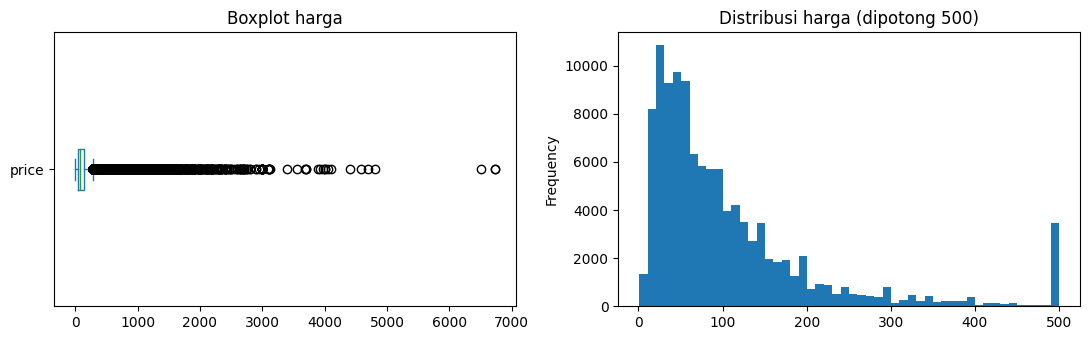

In [9]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
items["price"].plot.box(vert=False, ax=ax[0], title="Boxplot harga")
items["price"].clip(upper=500).plot.hist(bins=50, ax=ax[1], title="Distribusi harga (dipotong 500)")
plt.tight_layout()
plt.show()

## 5. Order payments

In [10]:
print(payments["payment_type"].value_counts())
print("\nPayment value = 0:", (payments["payment_value"] == 0).sum())
print("Installments = 0:", (payments["payment_installments"] == 0).sum())
print("Payment type 'not_defined':", (payments["payment_type"] == "not_defined").sum())
print("\nRata-rata baris pembayaran per order:",
      round(len(payments) / payments["order_id"].nunique(), 2))

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

Payment value = 0: 9
Installments = 0: 2
Payment type 'not_defined': 3

Rata-rata baris pembayaran per order: 1.04


## 6. Order reviews (cleaning utama)
Satu order bisa punya lebih dari satu review. Ambil review **terbaru** per order agar tidak terjadi duplikasi saat join.

In [11]:
print("Skor review unik:", sorted(reviews["review_score"].unique()))
cnt = reviews.groupby("order_id").size()
print("Order dengan >1 review:", (cnt > 1).sum(), "dari", len(cnt))

reviews_clean = (reviews.sort_values("review_answer_timestamp")
                        .drop_duplicates("order_id", keep="last"))
print("Setelah dedup:", reviews_clean.shape, "| order unik:", reviews_clean["order_id"].nunique())

# Kolom komentar tidak dibutuhkan untuk analisis ini
reviews_clean = reviews_clean[["review_id", "order_id", "review_score",
                               "review_creation_date", "review_answer_timestamp"]]

Skor review unik: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Order dengan >1 review: 547 dari 98673
Setelah dedup: (98673, 7) | order unik: 98673


## 7. Customers
`customer_id` unik per **pesanan**; `customer_unique_id` adalah pelanggan sebenarnya.

In [12]:
print("Baris customers:", len(customers))
print("customer_id unik:", customers["customer_id"].nunique())
print("customer_unique_id unik:", customers["customer_unique_id"].nunique())
print("\nTop 10 state:")
print(customers.groupby("customer_state")["customer_unique_id"].nunique()
      .sort_values(ascending=False).head(10))

Baris customers: 99441
customer_id unik: 99441
customer_unique_id unik: 96096

Top 10 state:
customer_state
SP    40302
RJ    12384
MG    11259
RS     5277
PR     4882
SC     3534
BA     3277
DF     2075
ES     1964
GO     1952
Name: customer_unique_id, dtype: int64


## 8. Products & category translation (cleaning utama)

In [13]:
print("Produk tanpa kategori:", products["product_category_name"].isna().sum())

missing_trans = set(products["product_category_name"].dropna()) - set(trans["product_category_name"])
print("Kategori tanpa terjemahan:", missing_trans)

Produk tanpa kategori: 610
Kategori tanpa terjemahan: {'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}


In [14]:
# Tambahkan terjemahan manual untuk kategori yang tidak ada di file translation
extra = pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos"],
    "product_category_name_english": ["pc_gamer", "portable_kitchen_food_preparers"]})
trans_clean = pd.concat([trans, extra]).drop_duplicates("product_category_name")

products_clean = products.merge(trans_clean, on="product_category_name", how="left")
products_clean["product_category_name"] = products_clean["product_category_name"].fillna("unknown")
products_clean["product_category_name_english"] = products_clean["product_category_name_english"].fillna("unknown")

print("Produk 'unknown':", (products_clean["product_category_name_english"] == "unknown").sum())
print("Jumlah kategori:", products_clean["product_category_name_english"].nunique())
print(products_clean["product_category_name_english"].value_counts().head(10))

Produk 'unknown': 610
Jumlah kategori: 74
product_category_name_english
bed_bath_table           3029
sports_leisure           2867
furniture_decor          2657
health_beauty            2444
housewares               2335
auto                     1900
computers_accessories    1639
toys                     1411
watches_gifts            1329
telephony                1134
Name: count, dtype: int64


## 9. Sellers & geolocation

In [15]:
print(sellers.head())
print("Seller unik:", sellers["seller_id"].nunique())
# geolocation dilewati (tidak dibutuhkan untuk analisis A-E)

                          seller_id  seller_zip_code_prefix  \
0  3442f8959a84dea7ee197c632cb2df15                   13023   
1  d1b65fc7debc3361ea86b5f14c68d2e2                   13844   
2  ce3ad9de960102d0677a81f5d0bb7b2d                   20031   
3  c0f3eea2e14555b6faeea3dd58c1b1c3                    4195   
4  51a04a8a6bdcb23deccc82b0b80742cf                   12914   

         seller_city seller_state  
0           campinas           SP  
1         mogi guacu           SP  
2     rio de janeiro           RJ  
3          sao paulo           SP  
4  braganca paulista           SP  
Seller unik: 3095


## 10. Validasi akhir
Sanity check: total revenue (harga saja, status delivered) seharusnya sekitar **13 juta BRL**.

In [16]:
# Integritas relasi
print("Item dengan order_id tidak ada di orders:",
      (~items["order_id"].isin(orders["order_id"])).sum())
print("Order tanpa item:", (~orders["order_id"].isin(items["order_id"])).sum())
print("Order tanpa customer:", (~orders["customer_id"].isin(customers["customer_id"])).sum())
print("Item dengan product_id tidak ada di products:",
      (~items["product_id"].isin(products["product_id"])).sum())

# Total revenue (delivered)
delivered_ids = orders.loc[orders["order_status"] == "delivered", ["order_id"]]
rev = items.merge(delivered_ids, on="order_id")
print(f"\nTotal revenue (delivered): {rev['price'].sum():,.2f}")
print(f"Jumlah order delivered   : {rev['order_id'].nunique():,}")
print(f"AOV                      : {rev['price'].sum() / rev['order_id'].nunique():,.2f}")

Item dengan order_id tidak ada di orders: 0
Order tanpa item: 775
Order tanpa customer: 0
Item dengan product_id tidak ada di products: 0

Total revenue (delivered): 13,221,498.11
Jumlah order delivered   : 96,478
AOV                      : 137.04


## 11. Simpan data yang sudah bersih

In [17]:
orders.to_csv(CLEAN + "orders_clean.csv", index=False)
items.to_csv(CLEAN + "order_items_clean.csv", index=False)
payments.to_csv(CLEAN + "order_payments_clean.csv", index=False)
reviews_clean.to_csv(CLEAN + "order_reviews_clean.csv", index=False)
customers.to_csv(CLEAN + "customers_clean.csv", index=False)
products_clean.to_csv(CLEAN + "products_clean.csv", index=False)
sellers.to_csv(CLEAN + "sellers_clean.csv", index=False)

print(sorted(os.listdir(CLEAN)))

['.gitkeep', 'customers_clean.csv', 'order_items_clean.csv', 'order_payments_clean.csv', 'order_reviews_clean.csv', 'orders_clean.csv', 'products_clean.csv', 'sellers_clean.csv']


## Ringkasan temuan pada data cleaning

1. Dari 99.441 order, 96.478 berstatus `delivered`. Sisanya (canceled, shipped, dll.) dikeluarkan dari analisis revenue.
2. Ada 8 order `delivered` tanpa tanggal sampai. Dikeluarkan dari analisis pengiriman.
3. Ada 547 order dengan lebih dari satu review. Saya ambil review terbaru agar tidak terjadi duplikasi saat join.
4. Ada 610 produk tanpa kategori. Diisi `unknown`.
5. Ada 2 kategori tanpa terjemahan (`pc_gamer` dan `portateis_cozinha_...`). Saya tambahkan terjemahannya manual.
6. Data 2016 sangat sedikit dan akhir 2018 tidak lengkap, sehingga analisis tren perlu hati-hati di periode itu.